In [1]:
import pandas as pd
import matplotlib.pyplot as plt

file = "Top ses.xlsx"

df = pd.read_excel(file, sheet_name="Top quarter europa")

print(df.columns)
df.head()

Index(['Unnamed: 0', 'Bottom quarter of ESCS 2022', 'Top quarter of ESCS 2022',
       'Bottom quarter of ESCS 2025', 'Top quarter of ESCS 2025', 'Top change',
       'Bottom change', 'Europe'],
      dtype='str')


,Unnamed: 0,Bottom quarter of ESCS 2022,Top quarter of ESCS 2022,Bottom quarter of ESCS 2025,Top quarter of ESCS 2025,Top change,Bottom change,Europe
0,Austria,425.98649,538.3424,430.54018,512.46584,-25.87656,4.55369,Europa
1,Belgium,424.79622,540.05433,433.28224,517.21775,-22.83658,8.48602,Europa
2,Bulgaria,344.55419,466.9111,353.10132,442.05217,-24.85893,8.54713,Europa
3,Croatia,442.92396,516.53108,421.77323,500.72686,-15.80422,-21.15073,Europa
4,Cyprus,345.04749,427.67078,363.37892,423.21619,-4.45459,18.33143,Europa


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Unnamed: 0                   35 non-null     str    
 1   Bottom quarter of ESCS 2022  35 non-null     object 
 2   Top quarter of ESCS 2022     35 non-null     object 
 3   Bottom quarter of ESCS 2025  35 non-null     float64
 4   Top quarter of ESCS 2025     35 non-null     float64
 5   Top change                   34 non-null     float64
 6   Bottom change                34 non-null     float64
 7   Europe                       35 non-null     str    
dtypes: float64(4), object(2), str(2)
memory usage: 2.3+ KB


In [3]:
df = df.rename(columns = {"Unnamed: 0": "Country"})

In [4]:
score_cols = [
    "Bottom quarter of ESCS 2022",
    "Top quarter of ESCS 2022",
    "Bottom quarter of ESCS 2025",
    "Top quarter of ESCS 2025",
    "Top change",
    "Bottom change"
]

for col in score_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Country                      35 non-null     str    
 1   Bottom quarter of ESCS 2022  34 non-null     float64
 2   Top quarter of ESCS 2022     34 non-null     float64
 3   Bottom quarter of ESCS 2025  35 non-null     float64
 4   Top quarter of ESCS 2025     35 non-null     float64
 5   Top change                   34 non-null     float64
 6   Bottom change                34 non-null     float64
 7   Europe                       35 non-null     str    
dtypes: float64(6), str(2)
memory usage: 2.3 KB


In [5]:
df[df["Country"]=="Sweden"]

,Country,Bottom quarter of ESCS 2022,Top quarter of ESCS 2022,Bottom quarter of ESCS 2025,Top quarter of ESCS 2025,Top change,Bottom change,Europe
32,Sweden,435.20712,544.46636,420.99529,512.06052,-32.40584,-14.21183,Europa


In [6]:
valid = df.dropna(subset=["Top change"]).copy()

In [7]:
print("number of countries:", len(valid))

number of countries: 34


In [8]:
print("Europe mean:", valid["Top change"].mean())

Europe mean: -20.72087029411766


In [9]:
print("Europe median:", valid["Top change"].median())

Europe median: -21.215899999999976


In [10]:
sweden_change = valid.loc[valid["Country"] == "Sweden", "Top change"].iloc[0]

In [11]:
print("Sweden:", sweden_change)

Sweden: -32.40584000000001


In [12]:
ranked = valid.sort_values("Top change", ascending = True).reset_index(drop =True)

In [13]:
ranked["Rank"] = ranked.index + 1

ranked[ranked["Country"] == "Sweden"]

,Country,Bottom quarter of ESCS 2022,Top quarter of ESCS 2022,Bottom quarter of ESCS 2025,Top quarter of ESCS 2025,Top change,Bottom change,Europe,Rank
5,Sweden,435.20712,544.46636,420.99529,512.06052,-32.40584,-14.21183,Europa,6


In [14]:
n_decline = (valid["Top change"] < 0).sum()
print("Countries with decline:", n_decline)

Countries with decline: 32


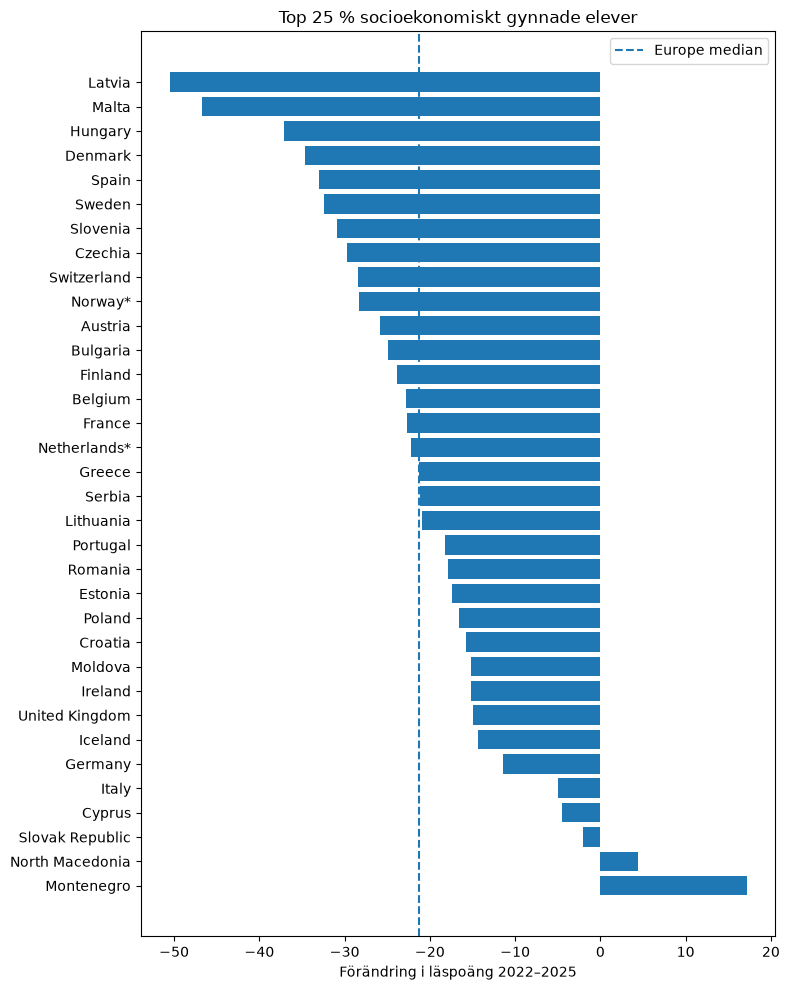

In [15]:
plot_df = ranked[["Country","Top change"]].copy()

plt.figure(figsize=(8, 10))
plt.barh(
    plot_df["Country"],
    plot_df["Top change"]
)
plt.axvline(
    valid["Top change"].median(),
    linestyle="--",
    label="Europe median"
)
plt.gca().invert_yaxis()

plt.xlabel("Förändring i läspoäng 2022–2025")
plt.title("Top 25 % socioekonomiskt gynnade elever")

plt.legend()
plt.tight_layout()
plt.show()

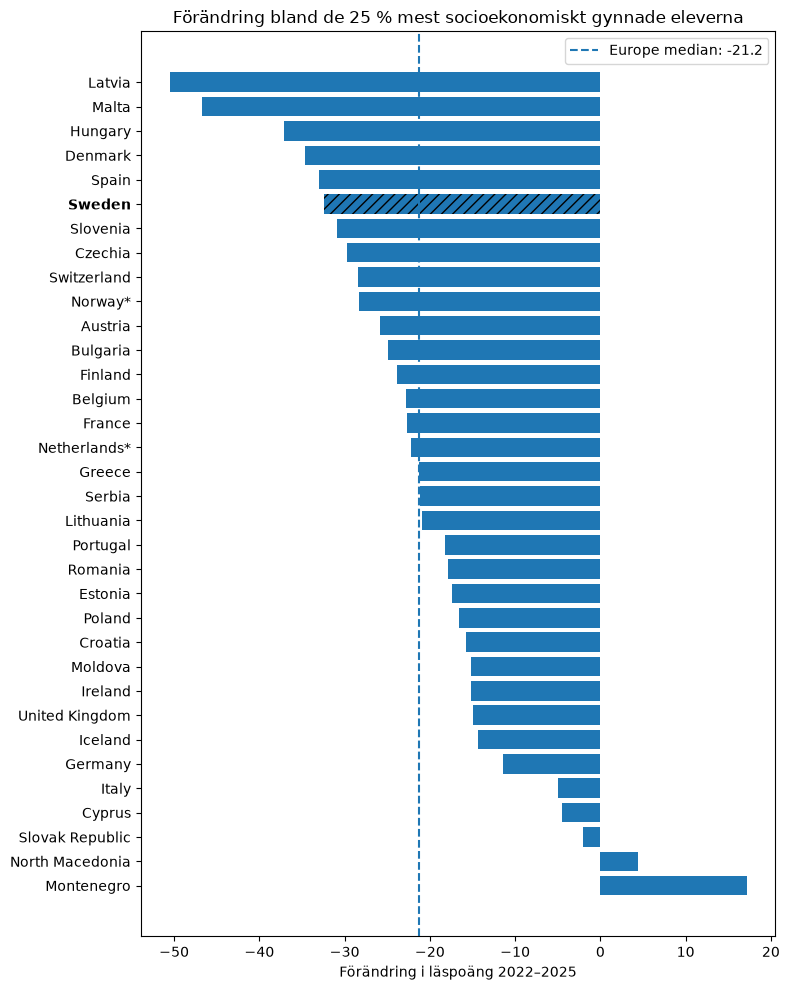

In [16]:
fig, ax = plt.subplots(figsize=(8, 10))

bars = ax.barh(
    plot_df["Country"],
    plot_df["Top change"]
)

# Đường median của châu Âu
europe_median = valid["Top change"].median()

ax.axvline(
    europe_median,
    linestyle="--",
    label=f"Europe median: {europe_median:.1f}"
)

# Đưa nước giảm mạnh nhất lên trên
ax.invert_yaxis()

# Làm nổi bật Sweden bằng hatch + viền
for bar, country in zip(bars, plot_df["Country"]):
    if country == "Sweden":
        bar.set_hatch("///")
        bar.set_linewidth(2)

# In đậm chữ Sweden trên trục Y
for label in ax.get_yticklabels():
    if label.get_text() == "Sweden":
        label.set_fontweight("bold")

ax.set_xlabel("Förändring i läspoäng 2022–2025")
ax.set_title(
    "Förändring bland de 25 % mest socioekonomiskt gynnade eleverna"
)

ax.legend()
plt.tight_layout()
plt.show()

In [17]:
compare = df.dropna(
    subset=["Top change", "Bottom change"]
).copy()

compare["Top_minus_bottom"] = (
    compare["Top change"] - compare["Bottom change"]
)

sweden_compare = compare.loc[
    compare["Country"] == "Sweden",
    ["Country", "Top change", "Bottom change", "Top_minus_bottom"]
]

sweden_compare

,Country,Top change,Bottom change,Top_minus_bottom
32,Sweden,-32.40584,-14.21183,-18.19401


In [18]:
n_top_fell_more = (
    compare["Top_minus_bottom"] < 0
).sum()

print("Countries where top 25% fell more:", n_top_fell_more)
print("Countries compared:", len(compare))

print(
    "Europe median difference:",
    compare["Top_minus_bottom"].median()
)

Countries where top 25% fell more: 32
Countries compared: 34
Europe median difference: -17.378785000000022


In [19]:
diff_ranked = compare.sort_values(
    "Top_minus_bottom",
    ascending=True
).reset_index(drop=True)

diff_ranked["Rank"] = diff_ranked.index + 1

diff_ranked[
    diff_ranked["Country"] == "Sweden"
]

,Country,Bottom quarter of ESCS 2022,Top quarter of ESCS 2022,Bottom quarter of ESCS 2025,Top quarter of ESCS 2025,Top change,Bottom change,Europe,Top_minus_bottom,Rank
14,Sweden,435.20712,544.46636,420.99529,512.06052,-32.40584,-14.21183,Europa,-18.19401,15


In [20]:
fig.savefig(
    "pisa_top25_europe_sweden.png",
    dpi=300,
    bbox_inches="tight"
)